<a href="https://colab.research.google.com/github/andrewj132/Workshops-Code-2627/blob/main/fill_in_blanks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI@UCI — Week 3: Intro to ML & Basic Classifiers
## From Intuition to Code

**Pipeline:** data → features + labels → feature space → train/test split → KNN → prediction → evaluation

We will use the same Cat vs Dog example from the slides to turn the main ideas of classification into code.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
rng = np.random.default_rng(7)

## 1. Examples become data
Each row is one **sample**. `ear_size` and `fur_length` are **features**. `label` is the answer we want to predict.

In [2]:
n = 40
cats = pd.DataFrame({'ear_size': rng.normal(6.4,1.0,n), 'fur_length': rng.normal(6.0,1.0,n), 'label':'cat'})
dogs = pd.DataFrame({'ear_size': rng.normal(4.5,1.0,n), 'fur_length': rng.normal(4.3,1.0,n), 'label':'dog'})
df = pd.concat([cats,dogs], ignore_index=True)
noise_idx = rng.choice(len(df), size=6, replace=False)
df.loc[noise_idx,'label'] = df.loc[noise_idx,'label'].map({'cat':'dog','dog':'cat'})
df.sample(8, random_state=3)

,ear_size,fur_length,label
61,3.600072,3.757108,cat
57,4.846680,4.026084,dog
77,3.642044,3.493154,dog
6,6.460144,6.859383,cat
45,3.385933,4.662840,cat
8,5.907793,5.358530,dog
35,5.592465,6.689404,cat
73,4.420819,4.307959,dog


## 2. Where does the data live?
When each feature becomes an axis, every sample becomes a point in **feature space**.

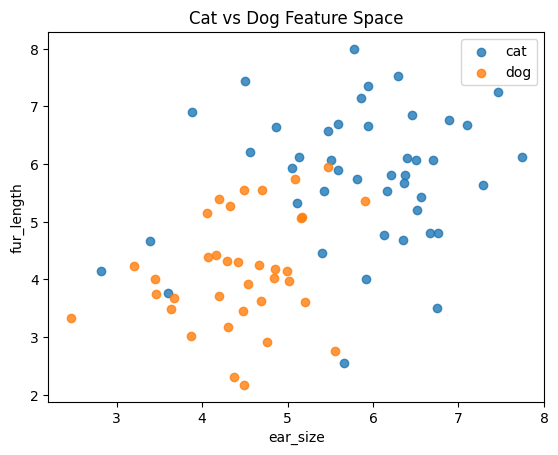

In [3]:
for label, group in df.groupby('label'):
    plt.scatter(group['ear_size'], group['fur_length'], label=label, alpha=0.8)
plt.xlabel('ear_size'); plt.ylabel('fur_length'); plt.title('Cat vs Dog Feature Space'); plt.legend(); plt.show()

In [4]:
X = df[['ear_size','fur_length']]
y = df['label']
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (80, 2) | y shape: (80,)


## 3. Split before you learn
The training set is available to the model. The test set stays hidden so we can check **generalization**.

In [7]:
# TODO 1:
# Split X and y into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state = 42,
    stratify=y
)
# Hint:
# - Keep 25% of the data for testing.
# - Use random_state=42 so everyone gets the same split.
# - Use stratify=y so the class proportions stay similar.

print("Train sample:", len(X_train))
print("Test sample:", len(X_test))


Train sample: 60
Test sample: 20


## 4. KNN intuition — do one prediction by hand

For a new point, KNN follows a simple process:

1. Measure the distance from the new point to the labeled training examples.
2. Keep the `k` nearest examples.
3. Count the labels of those neighbors.
4. Predict the majority label.

![KNN process](knn-process.svg)

If you want to review the intuition first, refer back to the Week 3 slide deck.

In [8]:
new_point = np.array([6.2,5.8])
distances = np.sqrt(np.sum((X_train.to_numpy() - new_point)**2, axis=1))
distance_table = X_train.copy()
distance_table['label'] = y_train.to_numpy()
distance_table['distance'] = distances
distance_table.sort_values('distance').head(8)

,ear_size,fur_length,label,distance
25,6.213069,5.803804,cat,0.013611
14,6.370748,5.811218,cat,0.171116
0,6.401230,6.110464,cat,0.369975
38,5.816400,5.749805,cat,0.386871
12,6.505414,6.074516,cat,0.410654
8,5.907793,5.358530,dog,0.529415
1,6.698746,6.063782,cat,0.564206
33,5.591163,5.902713,cat,0.617440


In [9]:
# TODO 2:
# Keep the 5 rows with the smallest distance values.
# Then count the labels and choose the most common label.
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_5.fit(X_train, y_train)
pred_5 = knn_5.predict(X_test)

train_acc_5 = accuracy_score(y_train, knn_5.predict(X_train))
test_acc_5 = accuracy_score(y_test, pred_5)

print("train acc:", train_acc_5)
print("test acc:", test_acc_5)
# Hint:
# - Use sort_values("distance") to order rows by distance.
# - Use head(5) to keep only the 5 nearest examples.
# - Use value_counts() to count how many cats and dogs are nearby.
# - Use idxmax() to get the label with the largest count.
nearest_5 = ...
votes = ...
manual_prediction = ...

print(votes)
print('Manual prediction:', manual_prediction)

train acc: 0.8666666666666667
test acc: 0.95
Ellipsis
Manual prediction: Ellipsis


## 5. Let scikit-learn do the same thing
This `k=5` example is completed first. Then you will repeat the pattern for other values of `k`.

In [10]:
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_5.fit(X_train, y_train)
pred_5 = knn_5.predict(X_test)
train_acc_5 = accuracy_score(y_train, knn_5.predict(X_train))
test_acc_5 = accuracy_score(y_test, pred_5)
print(f'k=5 training accuracy: {train_acc_5:.3f}')
print(f'k=5 test accuracy:     {test_acc_5:.3f}')

k=5 training accuracy: 0.867
k=5 test accuracy:     0.950


## 6. What does k change?
Compare a very local classifier (`k=1`) with a much broader one (`k=25`).

In [16]:
# TODO 3:
# Build a KNN classifier with k=1.
# Fit it using the training data, then measure both training and test accuracy.
#
knn_1 = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)

train_acc_1 = accuracy_score(y_train, knn_1.predict(X_train))

test_acc_1 = accuracy_score(y_test, knn_1.predict(X_test))

# Hint:
# - Create the model with KNeighborsClassifier(n_neighbors=1).
# - Call .fit(X_train, y_train).
# - Use .predict(...) inside accuracy_score(...) for both datasets.

print(f'k=1 training accuracy: {train_acc_1:.3f}')
print(f'k=1 test accuracy:     {test_acc_1:.3f}')

k=1 training accuracy: 1.000
k=1 test accuracy:     0.900


In [15]:
# TODO 4:
# Repeat the same process with k=25.
# Afterward, compare its training and test accuracy with k=1 and k=5.
#
# Hint:
# - Use KNeighborsClassifier(n_neighbors=25).
# - Fit on X_train and y_train.
# - Compute accuracy on both the training set and the test set.
knn_25 = KNeighborsClassifier(n_neighbors=25).fit(X_train, y_train)

train_acc_25 = accuracy_score(y_train, knn_25.predict(X_train))

test_acc_25 = accuracy_score(y_test, knn_25.predict(X_test))

print(f'k=25 training accuracy: {train_acc_25:.3f}')
print(f'k=25 test accuracy:     {test_acc_25:.3f}')

k=25 training accuracy: 0.817
k=25 test accuracy:     0.850


In [17]:
comparison = pd.DataFrame({'k':[1,5,25], 'training_accuracy':[train_acc_1,train_acc_5,train_acc_25], 'test_accuracy':[test_acc_1,test_acc_5,test_acc_25]})
comparison

,k,training_accuracy,test_accuracy
0,1,1.000000,0.90
1,5,0.866667,0.85
2,25,0.816667,0.85


### Discuss
Why can `k=1` look perfect on the training set without being the most trustworthy model on unseen data? This is the bridge from **memorization** to **generalization / overfitting**.

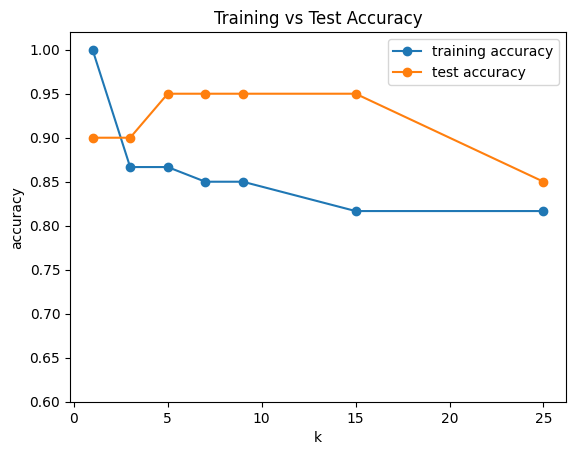

In [18]:
k_values=[1,3,5,7,9,15,25]; train_scores=[]; test_scores=[]
for k in k_values:
    model=KNeighborsClassifier(n_neighbors=k).fit(X_train,y_train)
    train_scores.append(accuracy_score(y_train,model.predict(X_train)))
    test_scores.append(accuracy_score(y_test,model.predict(X_test)))
plt.plot(k_values,train_scores,marker='o',label='training accuracy')
plt.plot(k_values,test_scores,marker='o',label='test accuracy')
plt.xlabel('k'); plt.ylabel('accuracy'); plt.title('Training vs Test Accuracy'); plt.ylim(0.6,1.02); plt.legend(); plt.show()

## 7. Predict a brand-new point

In [19]:
# TODO 5:
# Create one new sample with:
# - ear_size = 6.2
# - fur_length = 5.8
#
new_sample =  = pd.DataFrame{
    "ear_size": [0.2],
    "fur_length": [5.8]
}
prediction = knn_5.predict[new_sample]

print("prediction:", prediction[0])

# Then use the trained k=5 model to predict its label.
#
# Hint:
# Build a one-row pandas DataFrame with the same feature names
# used in X: "ear_size" and "fur_length".
new_sample = ...
prediction = ...

print('Prediction:', prediction[0])

SyntaxError: invalid syntax (1885029229.py, line 6)

## Wrap-up
You implemented: **data → features + labels → feature space → train/test split → KNN → prediction → accuracy**

> The goal is not to memorize the training data. The goal is to generalize.

---
## Visualize KNN decision regions

This visualization shows how the trained KNN classifier divides the feature space into predicted regions.

Compare the colored regions with the training examples and notice how nearby points influence the model's decision.

In [ ]:
def plot_knn_regions(model, X_data, y_data, title):
    # Set the plotting range slightly outside the training data.
    x0 = X_data["ear_size"].min() - 1
    x1 = X_data["ear_size"].max() + 1
    y0 = X_data["fur_length"].min() - 1
    y1 = X_data["fur_length"].max() + 1

    # Create a dense grid of points across the feature space.
    xx, yy = np.meshgrid(
        np.linspace(x0, x1, 220),
        np.linspace(y0, y1, 220)
    )

    grid = pd.DataFrame({
        "ear_size": xx.ravel(),
        "fur_length": yy.ravel()
    })

    # Ask the trained KNN model to classify every point in the grid.
    predictions = model.predict(grid)

    # Convert text labels into numbers so contourf can draw regions.
    z = (
        pd.Series(predictions)
        .map({"dog": 0, "cat": 1})
        .to_numpy()
        .reshape(xx.shape)
    )

    # Draw the model's predicted regions.
    plt.contourf(
        xx,
        yy,
        z,
        alpha=0.15,
        levels=[-0.5, 0.5, 1.5]
    )

    # Plot the original training examples on top.
    training_data = pd.concat([X_data, y_data], axis=1)

    for label, group in training_data.groupby("label"):
        plt.scatter(
            group["ear_size"],
            group["fur_length"],
            label=label,
            alpha=0.8
        )

    plt.xlabel("ear_size")
    plt.ylabel("fur_length")
    plt.title(title)
    plt.legend()
    plt.show()


plot_knn_regions(
    knn_5,
    X_train,
    y_train,
    "KNN Decision Regions (k=5)"
)